# Notebook 13: TimesFM consumption huis
---
- Zero-shot voorspelling van huis `consumption` met TimesFM 2.5 (voorgetraind, geen training)
- Zelfde testvensters als GRU-consumption, notebook 11 en 12
- Runtime (laden, compileren, voorspellen) bijgehouden met `time`

### 1. Literatuur
---
**Idee.** Net zoals grote taalmodellen op enorme hoeveelheden tekst zijn voorgetraind, zijn *time-series foundation models* voorgetraind op miljarden tijdreekspunten uit allerlei domeinen. Ze kunnen daarna zonder extra training (*zero-shot*) een nieuwe reeks voorspellen.

**TimesFM** (Das et al., 2024) is een decoder-only Transformer die, net als PatchTST, met patches werkt. Het is voorgetraind op een corpus van ~100 miljard tijdpunten (o.a. Google Trends, Wikipedia-paginaweergaven en synthetische reeksen). Op meerdere benchmarks kwam de zero-shot nauwkeurigheid in de buurt van, of boven, modellen die speciaal op die datasets waren getraind. Versie 2.5 (2025) heeft 200M parameters en kan tot 16k punten context gebruiken.

**Waarom dit kan helpen bij ons probleem.** De eerdere modellen leerden het gedrag uit 2024–2025 en hadden moeite met de veranderde situatie in 2026 (distribution shift). TimesFM leert niets van onze trainingsperiode: het normaliseert elke invoerreeks afzonderlijk (vergelijkbaar met RevIN, Kim et al., 2022) en baseert de voorspelling alleen op het recente niveau en patroon. Daarmee is het een goede test of het probleem in de *data/opzet* zit of in het *model*.

**Context-lengte.** Omdat er niet getraind wordt, kost een langere historie alleen rekentijd. Daarom worden twee varianten vergeleken: 7 dagen (gelijk aan de andere modellen) en 28 dagen (meer weekpatronen zichtbaar).

**Kanttekeningen.** TimesFM kent geen exogene variabelen in deze opzet (geen weer) en het weet niets over dit specifieke huis. Ook Chronos (Ansari et al., 2024) is een vergelijkbaar alternatief. Als referentie worden de *naive/seasonal naive*-baselines meegenomen (Hyndman & Athanasopoulos, 2021): een model is pas nuttig als het die verslaat.

**Bronnen**
- Ansari, A. F., Stella, L., Turkmen, C., et al. (2024). Chronos: Learning the Language of Time Series. *Transactions on Machine Learning Research (TMLR)*.
- Das, A., Kong, W., Sen, R., & Zhou, Y. (2024). A decoder-only foundation model for time-series forecasting. *Proceedings of the 41st International Conference on Machine Learning (ICML)*, PMLR 235.
- Google Research (2025). TimesFM 2.5 (`google/timesfm-2.5-200m-pytorch`). https://github.com/google-research/timesfm
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Kim, T., Kim, J., Tae, Y., Park, C., Choi, J.-H., & Choo, J. (2022). Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift. *ICLR*.

### 2. Inladen
---
- Libraries en paths
- Installatie (eenmalig): `pip install "timesfm[torch]"`. Als de klasse `TimesFM_2p5_200M_torch` daarna niet bestaat, installeer dan de nieuwste versie vanaf GitHub:
  `pip install "timesfm[torch] @ git+https://github.com/google-research/timesfm.git"`
- Bij de eerste keer wordt het model (~1 GB) gedownload van Hugging Face.
- Een GPU wordt sterk aangeraden; op CPU duurt voorspellen op de volledige testset lang (zie `SNELLE_TEST`).

In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import timesfm

start_notebook = time.perf_counter()
runtimes = {}
print("GPU:", torch.cuda.is_available())
assert hasattr(timesfm, "TimesFM_2p5_200M_torch"), "Oude timesfm-versie: installeer vanaf GitHub (zie hierboven)"

#Projectmap zoeken
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
split = pd.read_parquet(ROOT / "prepared_data" / "model_split.parquet").iloc[0]
DATA_DIR = ROOT / "prepared_data" / "forecast_targets_with_weather.parquet"
RESULTS_DIR = ROOT / "models" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Data:", DATA_DIR.resolve())

GPU: True
Data: C:\Users\casde\Desktop\Project3\Project3_Deel1\prepared_data\forecast_targets_with_weather.parquet


### 3. Voorspel instellingen
---

In [3]:
stap_per_dag = 24 * 12

aantal_dagen_input = 7
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3
horizon = aantal_dagen_forecast * stap_per_dag

stride_test = 12

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

CONTEXT_DAGEN = [7, 28]  #7 = gelijk aan andere modellen
SNELLE_TEST = False  #True = elke 4e forecast (voor CPU)
BATCH_SIZE = 32  #lager bij geheugenproblemen

### 4. Data en split
---
- Zelfde filter en split als GRU-consumption

In [4]:
t0 = time.perf_counter()
df = pd.read_parquet(DATA_DIR)
huis_cons = df[(df["location"] == "huis") & (df["target_type"] == "consumption")].copy()
#Zelfde filter als GRU-consumption en notebook 11, dus identieke testset
huis_cons = huis_cons.dropna(subset=["pow_imputed", "Windrichting", "WindSnelheid", "LuchtVochtigheid"])
huis_cons = huis_cons.sort_values("timestamp").reset_index(drop=True)
runtimes["data inladen"] = time.perf_counter() - t0
huis_cons = huis_cons[(huis_cons["timestamp"] >= split["train_start"]) & (huis_cons["timestamp"] < split["test_end"])].reset_index(drop=True)
y_arr = huis_cons["pow_imputed"].to_numpy(np.float32)
n = len(y_arr)
tijd = pd.to_datetime(huis_cons["timestamp"])
i_train = tijd.searchsorted(split["train_end"])
i_val = tijd.searchsorted(split["test_start"])
#Zelfde forecastmomenten als GRU-consumption en notebook 11
test_origins = i_val + input_len + np.arange(0, (n - i_val) - input_len - horizon + 1, stride_test)

print(huis_cons.shape)
print(f"n = {n} | train t/m {i_train} | val t/m {i_val} | test t/m {n}")
print("Start test:", huis_cons["timestamp"].iloc[i_val])
print(f"Aantal test-forecasts: {len(test_origins)}")

if SNELLE_TEST:
    test_origins = test_origins[::4]
    stride_test = stride_test * 4
    print("SNELLE_TEST: aantal forecasts teruggebracht naar", len(test_origins))

(48228, 16)
n = 48228 | train t/m 33240 | val t/m 40740 | test t/m 48228
Start test: 2026-03-18 11:00:00+01:00
Aantal test-forecasts: 385


### 5. Evaluatiefuncties
---
- Baselines, scores en plots

In [5]:
def baselines(origins):
    h = np.arange(horizon)
    t = origins[:, None] + h[None, :]
    k = h // stap_per_dag + 1
    dag = y_arr[t - stap_per_dag * k]
    week = y_arr[t - input_len]
    return dag, week


def echte_waarden(origins):
    return y_arr[origins[:, None] + np.arange(horizon)[None, :]]


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, s]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride_test)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res


def plot_voorspelling(voorspellingen, idx=0, titel="Voorspelling vs. echt"):
    o = test_origins[idx]
    hist = y_arr[o - input_len:o]
    echt = y_arr[o:o + horizon]
    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color="grey", label="Input (historie)")
    plt.plot(t_fc, echt, color="black", alpha=0.7, label="Echt")
    for naam, pred in voorspellingen.items():
        mae = np.abs(pred[idx] - echt).mean()
        plt.plot(t_fc, pred[idx], label=f"{naam} (MAE {mae:.0f} W)")
    plt.axvline(0, color="black", linestyle="--", alpha=0.5)
    plt.xlabel("Dagen t.o.v. start voorspelling")
    plt.ylabel("Verbruik (W)")
    plt.title(titel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def plot_mae_per_stap(voorspellingen, echt):
    plt.figure(figsize=(10, 3.5))
    for naam, pred in voorspellingen.items():
        plt.plot(np.arange(horizon) / stap_per_dag, np.abs(pred - echt).mean(axis=0), label=naam)
    plt.xlabel("Dagen vooruit")
    plt.ylabel("MAE (W)")
    plt.title("MAE per voorspelstap")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### 6. Model laden en compileren
---
- `normalize_inputs=True`: elke reeks wordt afzonderlijk genormaliseerd.
- `use_continuous_quantile_head=True`: geeft naast de mediaan ook kwantielen (10%–90%), gebruikt voor een onzekerheidsband in de plots.
- `max_context` en `max_horizon` zijn veelvouden van de patchgrootte; de horizon van 864 wordt daarna afgekapt.

In [6]:
t0 = time.perf_counter()
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", force_download=False)
runtimes["model laden"] = time.perf_counter() - t0

max_context = max(CONTEXT_DAGEN) * stap_per_dag
t0 = time.perf_counter()
model.compile(
    timesfm.ForecastConfig(
        max_context=int(np.ceil(max_context / 32) * 32),
        max_horizon=1024,
        normalize_inputs=True,
        per_core_batch_size=BATCH_SIZE,
        use_continuous_quantile_head=True,
        force_flip_invariance=True,
        infer_is_positive=True,
        fix_quantile_crossing=True,
    )
)
runtimes["compileren"] = time.perf_counter() - t0
print(f"Model laden: {runtimes['model laden']:.1f}s | compileren: {runtimes['compileren']:.1f}s")

config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\casde\.cache\huggingface\hub\models--google--timesfm-2.5-200m-pytorch. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWar

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

Model laden: 15.5s | compileren: 0.0s


### 7. Voorspellen op de testset
---
- Per forecastmoment krijgt TimesFM de laatste 7 of 28 dagen als invoer (alleen data van vóór het forecastmoment).
- Voorspellen gaat in blokken; de tijd wordt per contextlengte gemeten.

In [7]:
def voorspel_timesfm(origins, context_len, blok=512):
    mediaan, q10, q90 = [], [], []
    for i in range(0, len(origins), blok):
        inputs = [y_arr[o - context_len:o].astype(np.float32) for o in origins[i:i + blok]]
        punt, kwantielen = model.forecast(horizon=horizon, inputs=inputs)
        mediaan.append(np.asarray(punt)[:, :horizon])
        q10.append(np.asarray(kwantielen)[:, :horizon, 1])  #index 0 = gemiddelde, 1..9 = 10%..90%
        q90.append(np.asarray(kwantielen)[:, :horizon, 9])
    return np.vstack(mediaan), np.vstack(q10), np.vstack(q90)


echt_test = echte_waarden(test_origins)
voorspellingen, banden = {}, {}
for dagen in CONTEXT_DAGEN:
    naam = f"TimesFM {dagen}d"
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    pred, lo, hi = voorspel_timesfm(test_origins, dagen * stap_per_dag)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    runtimes[f"voorspellen {naam}"] = time.perf_counter() - t0
    voorspellingen[naam], banden[naam] = pred, (lo, hi)
    print(f"{naam}: {len(test_origins)} forecasts in {runtimes[f'voorspellen {naam}']:.1f}s "
          f"({runtimes[f'voorspellen {naam}'] / len(test_origins) * 1000:.1f} ms per forecast)")

base_dag, base_week = baselines(test_origins)

TimesFM 7d: 385 forecasts in 30.6s (79.4 ms per forecast)
TimesFM 28d: 385 forecasts in 32.5s (84.5 ms per forecast)


### 8. Resultaten
---

In [8]:
alle = {**voorspellingen, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
for naam in voorspellingen:
    resultaten.loc[naam, "trainingstijd (s)"] = 0.0
    resultaten.loc[naam, "voorspeltijd (s)"] = runtimes[f"voorspellen {naam}"]
resultaten = resultaten.round(1)
NOTEBOOK = "13_TimesFM_huis_cons"

#Model opslaan en bestandsgrootte meten
MODEL_DIR = ROOT / "models" / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def grootte_mb(pad):
    pad = Path(pad)
    if pad.is_dir():
        return sum(f.stat().st_size for f in pad.rglob("*") if f.is_file()) / 1e6
    return pad.stat().st_size / 1e6

#TimesFM wordt niet getraind, dus de grootte is die van de gedownloade checkpoint
try:
    from huggingface_hub import snapshot_download
    pad = snapshot_download("google/timesfm-2.5-200m-pytorch", local_files_only=True)
    for naam in voorspellingen:
        resultaten.loc[naam, "modelgrootte (MB)"] = grootte_mb(pad)
except Exception as e:
    print("Checkpoint niet gevonden:", e)
resultaten["modelgrootte (MB)"] = resultaten["modelgrootte (MB)"].round(3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "huis"
resultaten["target"] = "consumption"
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = (f"{huis_cons['timestamp'].iloc[i_val]:%Y-%m-%d} t/m "
                             f"{huis_cons['timestamp'].iloc[-1]:%Y-%m-%d}")
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / "13_timesfm_huis_cons.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
TimesFM 7d,13_TimesFM_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,272.299988,485.799988,257.299988,279.700012,279.799988,253.899994,446.399994,0.0,30.6,925.182
TimesFM 28d,13_TimesFM_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,267.600006,478.000000,261.500000,271.200012,270.200012,252.500000,449.600006,0.0,32.5,925.182
Persistence dag,13_TimesFM_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,305.000000,577.700012,295.000000,304.000000,316.100006,303.000000,568.000000,NaN,NaN,NaN
Persistence week,13_TimesFM_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,292.700012,557.700012,291.399994,289.500000,297.299988,293.600006,552.900024,NaN,NaN,NaN


In [9]:
#Dekking van de 10%-90% band: idealiter ligt ~80% van de echte waarden erbinnen
for naam, (lo, hi) in banden.items():
    dekking = ((echt_test >= lo) & (echt_test <= hi)).mean() * 100
    print(f"{naam}: {dekking:.1f}% van de echte waarden binnen de 10%-90% band")

TimesFM 7d: 74.3% van de echte waarden binnen de 10%-90% band
TimesFM 28d: 81.7% van de echte waarden binnen de 10%-90% band


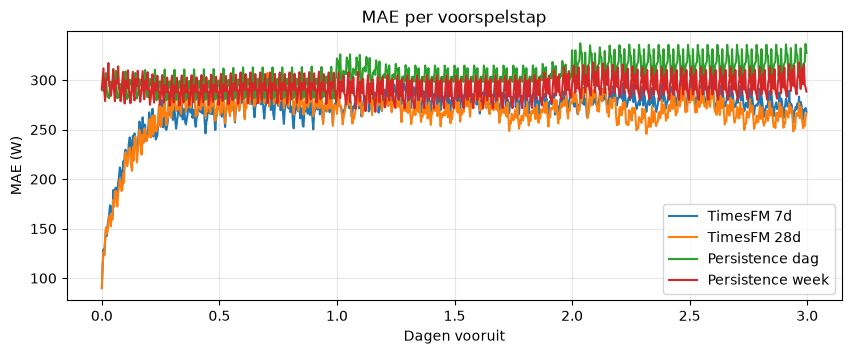

In [10]:
plot_mae_per_stap(alle, echt_test)

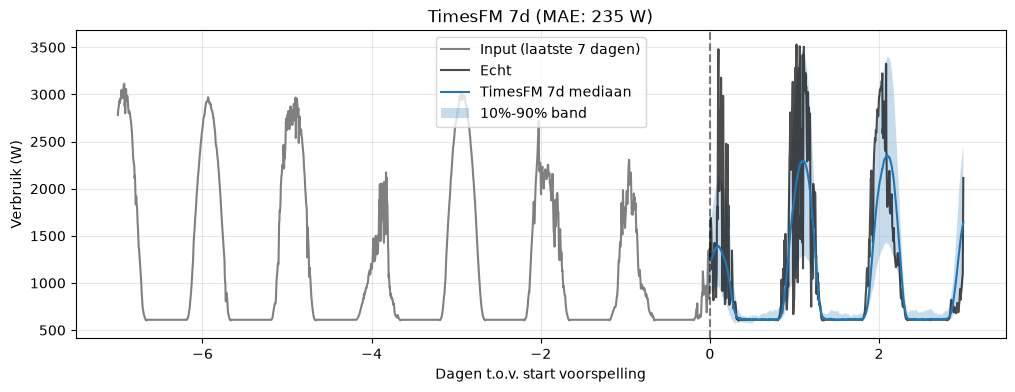

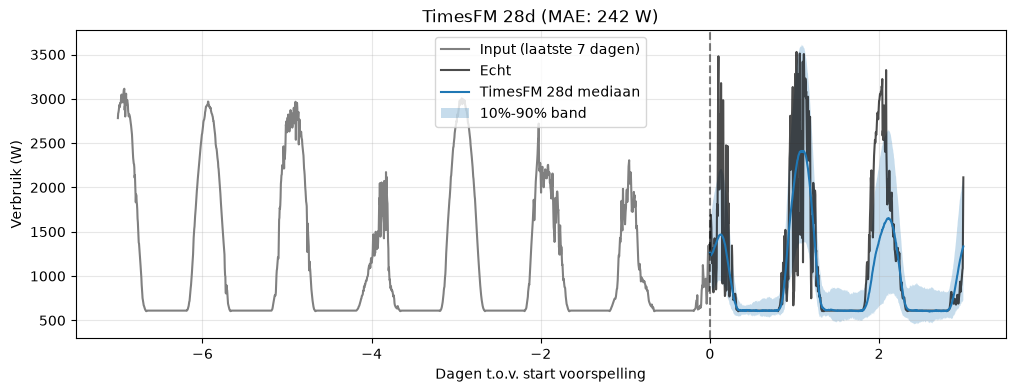

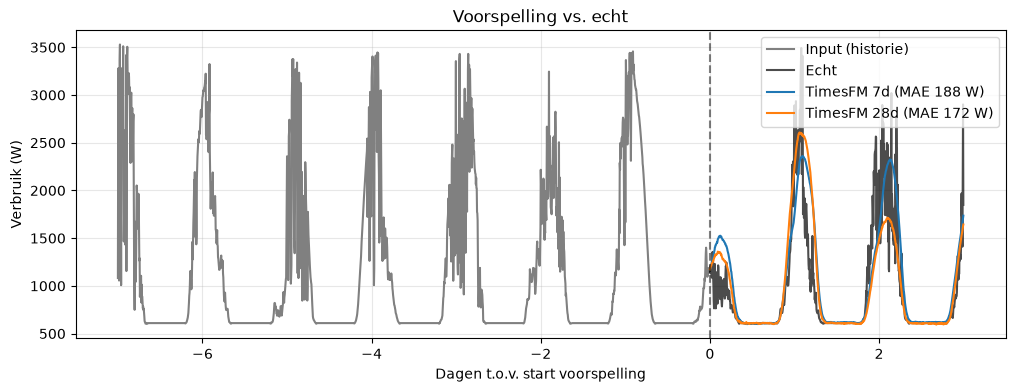

In [11]:
def plot_met_band(naam, idx=0):
    o = test_origins[idx]
    lo, hi = banden[naam]
    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag
    echt = y_arr[o:o + horizon]
    mae = np.abs(voorspellingen[naam][idx] - echt).mean()

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, y_arr[o - input_len:o], color="grey", label="Input (laatste 7 dagen)")
    plt.plot(t_fc, echt, color="black", alpha=0.7, label="Echt")
    plt.plot(t_fc, voorspellingen[naam][idx], label=f"{naam} mediaan")
    plt.fill_between(t_fc, lo[idx], hi[idx], alpha=0.25, label="10%-90% band")
    plt.axvline(0, color="black", linestyle="--", alpha=0.5)
    plt.xlabel("Dagen t.o.v. start voorspelling")
    plt.ylabel("Verbruik (W)")
    plt.title(f"{naam} (MAE: {mae:.0f} W)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

for naam in voorspellingen:
    plot_met_band(naam, idx=0)
plot_voorspelling(voorspellingen, idx=len(test_origins) // 2)

### 9. Runtime overzicht
---

In [12]:
runtimes["totaal notebook"] = time.perf_counter() - start_notebook
runtime_df = pd.DataFrame({"seconden": runtimes}).assign(minuten=lambda d: d["seconden"] / 60).round(2)
runtime_df

,seconden,minuten
data inladen,0.13,0.00
model laden,15.52,0.26
compileren,0.00,0.00
voorspellen TimesFM 7d,30.55,0.51
voorspellen TimesFM 28d,32.55,0.54
totaal notebook,79.90,1.33
